In [1]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files
import urllib.request

In [2]:
uploaded = files.upload()

filename = next(iter(uploaded))

image = cv2.imread(filename)

if image is None:
    raise ValueError("Image could not be loaded.")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print("Image uploaded successfully!")

Saving 1000003432.jpg to 1000003432.jpg
Image uploaded successfully!


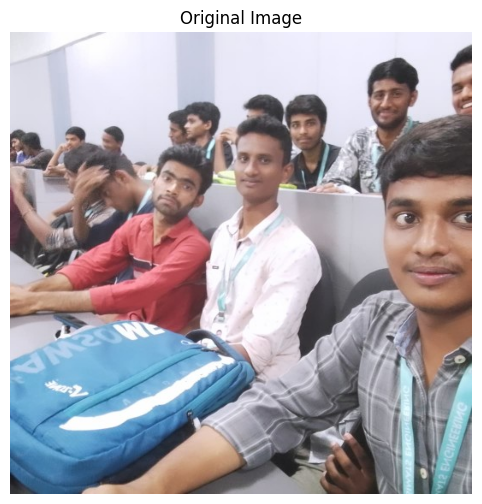

In [3]:
plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()

In [6]:
import cv2

print("OpenCV location:", cv2.__file__)
print("OpenCV version:", getattr(cv2, "__version__", "Unknown"))
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))
print("Module name:", cv2.__name__)

OpenCV location: /usr/local/lib/python3.13/dist-packages/cv2/__init__.py
OpenCV version: 5.0.0
CascadeClassifier available: False
Module name: cv2


In [8]:
import cv2

print("OpenCV version:", getattr(cv2, "__version__", "Not found"))
print("OpenCV file location:", cv2.__file__)
print("Module name:", cv2.__name__)
print("CascadeClassifier available:", hasattr(cv2, "CascadeClassifier"))

OpenCV version: 5.0.0
OpenCV file location: /usr/local/lib/python3.13/dist-packages/cv2/__init__.py
Module name: cv2
CascadeClassifier available: False


In [1]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94


In [3]:
!pip install opencv-python-headless==4.11.0.86


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.0/50.0 MB 38.4 MB/s  0:00:01


In [1]:
import cv2

print("OpenCV Version:", cv2.__version__)
print("CascadeClassifier:", hasattr(cv2, "CascadeClassifier"))

assert hasattr(cv2, "CascadeClassifier"), "OpenCV installation is not correct!"

print("OpenCV is working successfully!")

OpenCV Version: 4.11.0
CascadeClassifier: True
OpenCV is working successfully!


In [2]:
import urllib.request
import cv2

urllib.request.urlretrieve(
    "https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml",
    "/content/haarcascade_frontalface_default.xml"
)

urllib.request.urlretrieve(
    "https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_smile.xml",
    "/content/haarcascade_smile.xml"
)

face_cascade = cv2.CascadeClassifier(
    "/content/haarcascade_frontalface_default.xml"
)

smile_cascade = cv2.CascadeClassifier(
    "/content/haarcascade_smile.xml"
)

print("Face classifier:", not face_cascade.empty())
print("Smile classifier:", not smile_cascade.empty())

Face classifier: True
Smile classifier: True


In [4]:
import cv2
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))
image = cv2.imread(filename)

if image is None:
    raise ValueError("Unable to read image. Upload a valid JPG or PNG.")

gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print("Image loaded successfully!")
print("Grayscale conversion completed!")

Saving 1000003436.jpg to 1000003436.jpg
Image loaded successfully!
Grayscale conversion completed!


In [5]:
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(50, 50)
)

result = image.copy()
smile_count = 0

for (x, y, w, h) in faces:

    cv2.rectangle(
        result, (x, y), (x+w, y+h), (255, 0, 0), 2
    )

    face_gray = gray[y:y+h, x:x+w]

    smiles = smile_cascade.detectMultiScale(
        face_gray,
        scaleFactor=1.7,
        minNeighbors=20,
        minSize=(25, 15)
    )

    for (sx, sy, sw, sh) in smiles:
        cv2.rectangle(
            result,
            (x+sx, y+sy),
            (x+sx+sw, y+sy+sh),
            (0, 255, 0),
            2
        )
        smile_count += 1

print("Faces detected:", len(faces))
print("Smiles detected:", smile_count)

Faces detected: 3
Smiles detected: 0


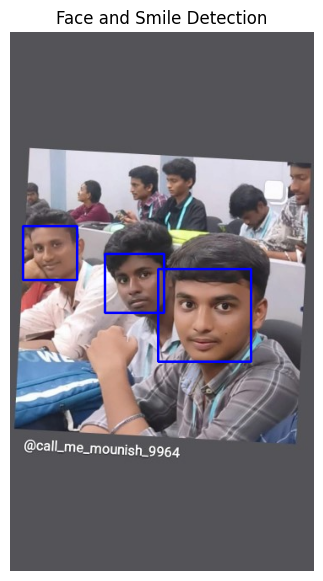

In [6]:
plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Face and Smile Detection")
plt.axis("off")
plt.show()